<a href="https://colab.research.google.com/github/aashishneupanecs24-creator/BIOS-LAB-1BF24CS004/blob/main/Cuckoo_Search.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best Solution: [-0.30443266  0.24915312]
Minimum Fitness: 0.1547565186728149


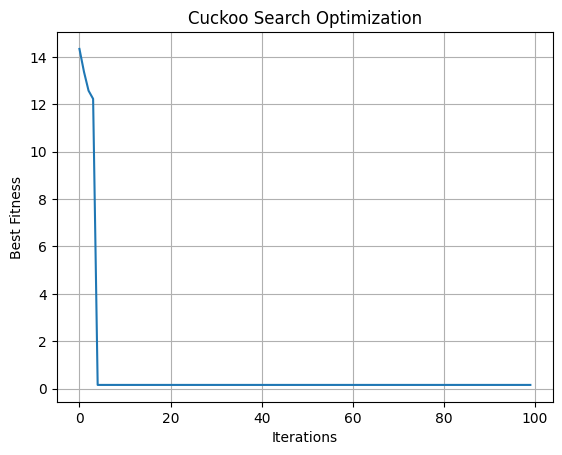

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import math

# Objective function
def fitness(x):
    return np.sum(x ** 2)

# Levy flight calculation
def levy_flight():
    beta = 1.5
    sigma = (
        math.gamma(1 + beta) * np.sin(np.pi * beta / 2) /
        (math.gamma((1 + beta) / 2) * beta *
         2 ** ((beta - 1) / 2))
    ) ** (1 / beta)

    u = np.random.normal(0, sigma, 2)
    v = np.random.normal(0, 1, 2)

    return u / (np.abs(v) ** (1 / beta))

# Parameters
n = 25
iterations = 100
pa = 0.25
alpha = 0.01
lower, upper = -10, 10

np.random.seed(42)

# Generate random nests
nests = np.random.uniform(lower, upper, (n, 2))
best_history = []

# Cuckoo Search
for t in range(iterations):

    for i in range(n):
        new_nest = nests[i] + alpha * levy_flight() * (
            nests[i] - nests[np.argmin(
                [fitness(x) for x in nests])]
        )

        new_nest = np.clip(new_nest, lower, upper)

        j = np.random.randint(n)

        if fitness(new_nest) < fitness(nests[j]):
            nests[j] = new_nest

    # Abandon some nests and create new ones
    for i in range(n):
        if np.random.rand() < pa:
            nests[i] = np.random.uniform(lower, upper, 2)

    # Find the best nest
    best = nests[np.argmin([fitness(x) for x in nests])]
    best_history.append(fitness(best))

# Final result
best = nests[np.argmin([fitness(x) for x in nests])]

print("Best Solution:", best)
print("Minimum Fitness:", fitness(best))

# Plot convergence graph
plt.plot(best_history)
plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.title("Cuckoo Search Optimization")
plt.grid()
plt.show()
